# Tutorial 03 — Asteroid thermal model: a generic body on a Keplerian orbit

This notebook runs PTM3D's **generic-body** ("asteroid") thermal path end to end,
from a config file to a physically-interpreted plot, using nothing but the CPU
core and a Python/numpy/matplotlib stack.

**Companion .yaml files:**
[`examples/quickstart_asteroid_diurnal.yaml`](../../../examples/quickstart_asteroid_diurnal.yaml)
(TI = 100 SI) and
[`examples/quickstart_asteroid_diurnal_ti200_check.yaml`](../../../examples/quickstart_asteroid_diurnal_ti200_check.yaml)
(TI = 200 SI, otherwise identical — used in Section 4 to prove a thermophysical
edit actually reached the solver).

**Cost:** two ~25–35 s CPU-only runs (1280-face icosphere, 2 rotations of
output after a 50-rotation equilibration) — a few minutes total including
plotting, laptop-friendly.

**Related tutorials:** [02 — lunar diurnal run](../02_lunar_diurnal_icosphere.md)
(a *built-in* body, for contrast), [06 — interpreting the outputs](../06_interpreting_outputs.md)
(the general binary-format reference this notebook's readers implement in
Python), and [`docs/KNOWN_LIMITATIONS.md`](../../KNOWN_LIMITATIONS.md) (PTM-67,
discussed in depth in Section 3).

## Learning goals

By the end of this notebook you will be able to:

1. Configure and run PTM3D's **generic-body** (Keplerian-orbit, non-built-in
   body) thermal path, and state exactly what external data it does and does
   not need.
2. Explain **PTM-67**: why most of a config's top-level `thermophysical:`
   block is inert for a generic body, and why `generic_body.surface:` is the
   section that actually reaches the solver — and, going one step further,
   why the run log's own banner **cannot** confirm a thermal-inertia edit
   took effect, and what to run instead to confirm it.
3. Read every file PTM3D writes to an output directory using nothing but the
   Python standard library and numpy (no PTM3D-specific tooling required).
4. Produce the three standard asteroid-thermophysics plots: a surface
   temperature map at one epoch, the equatorial diurnal temperature curve,
   and the **thermal-inertia signature plot** — the morning/afternoon
   asymmetry that is the actual observable behind asteroid radiometry and the
   Yarkovsky effect.
5. Connect thermal inertia to real observations, and know which knobs
   (thermal inertia, spin rate, orbital eccentricity) to turn next.

## 1. Environment check

**What this tutorial needs, and — just as important — what it does *not*
need.** A Keplerian-orbit generic body needs no SPICE planetary ephemeris and
no DEM: the orbit is propagated analytically (two-body Kepler), and the shape
is a synthetic icosphere generated at run time. That is the selling point of
this config relative to the Moon/Horizons quickstarts, which need 44 MB–1.1 GB
of SPICE kernel data before they can run at all.

The one piece of external data this notebook verifies below is **the
universal leapseconds kernel** (`naif0012.tls`, ~5 KB) — even Keplerian mode
uses SPICE's `str2et_c` to parse the config's UTC `start_time` string, and
that call fails without it. This was not assumed; it was found empirically
while developing this tutorial (a `FATAL: SPICE str2et_c failed ...
SPICE(NOLEAPSECONDS)` on the very first run) and is fetched + hash-verified
below rather than glossed over.

In [1]:
import sys, os, subprocess, struct, hashlib, glob, time
from pathlib import Path

import numpy as np
import matplotlib
import matplotlib.pyplot as plt

print("Python     :", sys.version.split()[0])
print("numpy      :", np.__version__)
print("matplotlib :", matplotlib.__version__)


def find_repo_root(start: Path) -> Path:
    # Walk up from `start` until a directory looks like the PTM3D repo root.
    p = start.resolve()
    for candidate in [p, *p.parents]:
        if (candidate / "CMakeLists.txt").exists() and (candidate / "examples").is_dir():
            return candidate
    raise RuntimeError(f"Could not locate the PTM3D repo root walking up from {start}")


REPO_ROOT = find_repo_root(Path.cwd())
print("Repo root  :", REPO_ROOT)

Python     : 3.8.18
numpy      : 1.24.4
matplotlib : 3.7.5
Repo root  : /Users/paha3326/Projects/ptm-nb-asteroid


In [2]:
BIN = REPO_ROOT / "build" / "bin" / "ptm_thermal_sim"
if not BIN.exists():
    raise SystemExit(
        f"ptm_thermal_sim not found at {BIN}.\n"
        "Build the CPU-only core first (see INSTALL.md 'TL;DR (Linux/macOS, CPU-only)'):\n"
        "  cmake -S . -B build -DCMAKE_BUILD_TYPE=Release -DPTM_ENABLE_GPU=OFF \\\n"
        "        -DPTM_ARCH_NATIVE=OFF -DCSPICE_ROOT=/path/to/cspice\n"
        "  cmake --build build --target ptm_thermal_sim -j"
    )


def md5_of(path):
    h = hashlib.md5()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()


commit = subprocess.run(["git", "rev-parse", "--short", "HEAD"], cwd=REPO_ROOT,
                         capture_output=True, text=True).stdout.strip()
help_run = subprocess.run([str(BIN), "--help"], capture_output=True, text=True)

print("Binary     :", BIN)
print("  md5      :", md5_of(BIN))
print("  commit   :", commit or "(git rev-parse failed -- not fatal)")
print("  --help rc:", help_run.returncode, "(0 = OK)")
assert help_run.returncode == 0, "ptm_thermal_sim --help did not exit 0 -- broken build"
print("\nThis tutorial runs the CPU core throughout (thermal.use_gpu: false in both "
      "configs) — deliberate, so it never competes with a GPU campaign for the card.")

Binary     : /Users/paha3326/Projects/ptm-nb-asteroid/build/bin/ptm_thermal_sim
  md5      : 80589a79d1cf32d674d56a0194f11597
  commit   : 7fd214f
  --help rc: 0 (0 = OK)

This tutorial runs the CPU core throughout (thermal.use_gpu: false in both configs) — deliberate, so it never competes with a GPU campaign for the card.


In [3]:
import urllib.request

LSK = REPO_ROOT / "data" / "kernels" / "lsk" / "naif0012.tls"
LSK_URL = "https://naif.jpl.nasa.gov/pub/naif/generic_kernels/lsk/naif0012.tls"
LSK_SHA256 = "678e32bdb5a744117a467cd9601cd6b373f0e9bc9bbde1371d5eee39600a039b"  # pinned,
    # matches scripts/fetch_kernels.py's own pinned hash for this file


def sha256_of(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()


LSK.parent.mkdir(parents=True, exist_ok=True)
if LSK.exists() and sha256_of(LSK) == LSK_SHA256:
    print("Leapseconds kernel already present and hash-verified:", LSK)
else:
    print("Fetching the universal leapseconds kernel (one-time, ~5 KB)...")
    urllib.request.urlretrieve(LSK_URL, LSK)
    digest = sha256_of(LSK)
    assert digest == LSK_SHA256, f"sha256 mismatch: got {digest}, expected {LSK_SHA256}"
    print("Verified sha256:", digest)

print(f"\nTotal external data this tutorial required: 1 file, {LSK.stat().st_size} bytes.")
print("No SPICE planetary/lunar ephemeris, no DEM, no albedo/property maps —")
print("confirmed directly in the config walkthrough below (ephemeris_source: keplerian,")
print("generic_body.config_file: '', use_albedo_map: false).")

Leapseconds kernel already present and hash-verified: /Users/paha3326/Projects/ptm-nb-asteroid/data/kernels/lsk/naif0012.tls

Total external data this tutorial required: 1 file, 5257 bytes.
No SPICE planetary/lunar ephemeris, no DEM, no albedo/property maps —
confirmed directly in the config walkthrough below (ephemeris_source: keplerian,
generic_body.config_file: '', use_albedo_map: false).


## 2. Config walkthrough

The full config, as shipped:

In [4]:
cfg_path = REPO_ROOT / "examples" / "quickstart_asteroid_diurnal.yaml"
print(cfg_path.read_text())

# PTM3D quickstart: a generic-body (Keplerian) asteroid diurnal run on a small
# icosphere (ico3, 1280 faces).
#
# Laptop-friendly (CPU-only, <1 GB RAM; ~23 s measured on an 8-core machine
# with thermal.threads=4, well under a minute of wall time).
# SELF-CONTAINED: unlike the Moon/Horizons quickstarts, this run needs NO
# external data at all — no SPICE kernels, no DEM, no albedo/property maps.
# The body is fictional (there is no real "Quickstart Asteroid"); its orbit is
# propagated analytically (Keplerian two-body) and its shape is a synthetic
# icosphere, so nothing outside this file is fetched or required.
#
# All paths are relative — run FROM THE REPOSITORY ROOT:
#
#     ./build/bin/ptm_thermal_sim --config examples/quickstart_asteroid_diurnal.yaml
#
# Outputs land in output/quickstart_asteroid_diurnal/ (per-face statistics +
# per-timestep binaries). See docs/tutorials/notebooks/03_asteroid_thermal.ipynb
# for a full walkthrough of the outputs.
#
# ----------------------------

### Shape, orbit, spin

- **Shape**: a synthetic icosphere, `resolution: 3` (level-3 subdivision =
  1280 faces) — small enough to run on a laptop CPU in seconds, per
  `mesh.resolution` in `src/cpp/tools/config_parser.h`.
- **Orbit** (`generic_body.orbit`): `a = 2.7 AU`, `e = 0` (circular — an
  eccentric variant is Exercise 3), `i = 8°`. This is a *generic* mid-main-belt
  placement (between Vesta at 2.36 AU and the Themis family near 3.1 AU), not
  tuned to any real object. The solar constant there is
  $S = 1361/2.7^2 \approx 187\ \mathrm{W\,m^{-2}}$ — about 7.3% of Earth's —
  which is *why* thermal-infrared radiometry, not visible photometry alone,
  is how real programs measure asteroid surface properties: these bodies are
  cold and (being dark) comparatively IR-bright.
- **Spin** (`generic_body.spin`): `period_hours = 5.0` (a fast rotator, typical
  of a small NEA/main-belt fragment) with `pole_dec_deg = 90` — the spin axis
  is normal to the reference frame, i.e. **zero obliquity**. That pins the
  sub-solar latitude at the equator for the whole run, so the *only*
  time-dependence at this (orbit-frozen, sub-day) timescale is the diurnal
  cycle — deliberately, to isolate the signal this tutorial is about.

### Thermophysical properties — and PTM-67

This is the tutorial's central teaching point. **Thermal inertia**,
$$TI = \sqrt{k \, \rho \, c_p} \quad \left[\mathrm{J\,m^{-2}\,K^{-1}\,s^{-1/2}}\right],$$
is *the* asteroid-surface property radiometry actually measures: it controls
how much a surface's temperature **lags** a fast-varying insolation cycle,
which is exactly what regolith/rock/bare-rock discrimination (Delbo et al.
2007, 2015) is built on.

The config sets `ks = kd = 0.008333 W/m/K`, `rhos = rhod = 1500 kg/m³`,
`cp0 = 800 J/kg/K`, `chi = 0` (no $T^3$ radiative-conductivity enhancement),
giving

$$TI = \sqrt{0.008333 \times 1500 \times 800} = 100.0\ \mathrm{SI\ exactly},$$

constant with depth *and* temperature — `ks == kd` and `rhos == rhod`
deliberately collapse PTM3D's usual two-layer regolith profile to one
homogeneous slab, so there is exactly one TI number to reason about. TI = 100
sits in the textbook regolith range (loose lunar-like regolith ≈ 50 SI, bare
rock/boulders ≈ 400–2500 SI) and is well inside this solver's validated
working range (~32–316 SI, from prior extreme-TI numerical-stability testing
on this engine's generic-body path).

**Now the landmine (PTM-67, [`docs/KNOWN_LIMITATIONS.md`](../../KNOWN_LIMITATIONS.md)):**
for a *generic* body, the plain-named properties in a conventional top-level
`thermophysical:` block (`ks`, `kd`, `H`, `rhos`, `rhod`, `cp0`, `Qb`, `chi`,
`albedo`, `emissivity`) are **not read at all** — only `generic_body.surface:`
is. This config deliberately has **no such block** beyond one key
(`use_default_albedo: false`, which *is* read on every body type, to stop the
engine wasting a lookup for a per-body albedo map that cannot exist for a
fictional body) — shipping a `thermophysical:` block full of plausible-looking
but inert keys would be exactly the kind of silent, misleading config PTM-67
warns about.

### The habit this tutorial wants you to leave with: banner-checking

Every PTM3D run prints a block that starts `Using generic body: ...`. It is
worth grepping for on every run, because it is your **only** confirmation
that the generic-body path engaged at all (rather than silently falling back
to Europa-placeholder defaults, the historical failure mode this path had).
Section 4 runs the model and shows you exactly what that block does and does
**not** confirm.

## 3. Run it — and confirm the settings actually took effect

Two runs: the shipped TI = 100 SI config, then an otherwise-identical TI = 200
SI variant (`examples/quickstart_asteroid_diurnal_ti200_check.yaml`, `ks`/`kd`
scaled 4×). Running both is not optional flourish — it is how we are about to
find out that **the run log cannot confirm a thermal-inertia edit landed**,
and what to do about that.

In [5]:
def run_ptm(config_rel_path, label):
    cfg = REPO_ROOT / config_rel_path
    t0 = time.time()
    proc = subprocess.run([str(BIN), "--config", str(cfg)], cwd=REPO_ROOT,
                           capture_output=True, text=True)
    wall = time.time() - t0
    print(f"[{label}] rc={proc.returncode}  wall={wall:.1f} s")
    if proc.returncode != 0:
        print(proc.stdout[-3000:])
        print(proc.stderr[-3000:])
        raise RuntimeError(f"{label} failed, rc={proc.returncode}")
    return proc.stdout, wall


stdout_base, wall_base = run_ptm("examples/quickstart_asteroid_diurnal.yaml", "TI=100 (base)")

[TI=100 (base)] rc=0  wall=21.3 s


In [6]:
stdout_ti200, wall_ti200 = run_ptm(
    "examples/quickstart_asteroid_diurnal_ti200_check.yaml", "TI=200 (check)")

print(f"\nTotal wall time, both runs: {wall_base + wall_ti200:.1f} s")

[TI=200 (check)] rc=0  wall=21.2 s

Total wall time, both runs: 42.5 s


**Banner check.** Here is the *entire* `Using generic body:` block from the
TI = 100 run:

In [7]:
lines = stdout_base.splitlines()
start = next(i for i, l in enumerate(lines) if l.startswith("Using generic body"))
banner = lines[start:start + 10]
print("\n".join(banner))

Using generic body: Quickstart Asteroid
  Semi-major axis: 2.7 AU
  Eccentricity: 0
  Spin period: 5 hours
  Solar constant: 186.694 W/m^2
  Synodic day: 5.00064 hours
  Albedo: 0.05
  Emissivity: 0.95
  Body radius: 5 km
  Ephemeris: Keplerian


It confirms the body name, orbit, spin period, solar constant, albedo,
emissivity, radius, and ephemeris mode — genuinely useful, and worth grepping
for on every run. **It does not mention `ks`, `kd`, `rhos`, `rhod`, `cp0`,
`Qb`, or `chi` at all** — grep the full stdout below and there is nothing to
find (this was verified while writing this tutorial, not assumed):

In [8]:
hits = [l for l in stdout_base.splitlines()
        if any(tok in l for tok in (" ks ", " ks=", "ks:", "kd:", "rhos", "rhod", "cp0", " Qb", "chi ="))]
print(f"{len(hits)} log lines mention ks/kd/rhos/rhod/cp0/Qb/chi by name.")
for h in hits:
    print(" ", h)

0 log lines mention ks/kd/rhos/rhod/cp0/Qb/chi by name.


So: **there is no log line to grep for a thermal-inertia edit.** The only
honest way to confirm one took effect is to look at the physics — run the
same setup at two thermal inertias and check that the *output* moved the way
conduction theory says it must (smaller diurnal amplitude, later peak, at
higher TI). That is exactly what the rest of this notebook does; the QA cell
right below is the minimal version of that check.

### QA: did it actually change? (and a caveat this tutorial hit for real)

The first version of this check compared the **whole-body** minimum/maximum
temperature between the two runs and got a **wrong-signed** result — the
global `temperature_min` got *colder*, not warmer, at higher TI, which is
backwards. The cause: at `pole_dec_deg = 90` (zero obliquity) the poles see
the Sun at ~0° elevation essentially all the time — a permanent grazing-
incidence numerical edge case, unrelated to the conduction physics this
tutorial teaches, and it dominates the whole-body extremum. Restricting to
an **equatorial band** (`|lat| < 10°`) fixes it — reported below, not
silently swapped in.

In [9]:
def load_bin(path):
    # 4-byte int32 face-count header + n x float32, little-endian (see
    # docs/tutorials/06_interpreting_outputs.md).
    with open(path, "rb") as f:
        n = np.frombuffer(f.read(4), dtype="<i4")[0]
        vals = np.frombuffer(f.read(4 * int(n)), dtype="<f4")
    assert vals.size == n, f"truncated file {path}: {vals.size} of {n} values"
    return vals


def read_ply_face_latlon(path):
    # PTM3D mesh.ply: binary_little_endian, vertex = 6 float64 (xyz+normal),
    # face = uchar(3) + 3x int32 indices + float32 latitude + float32 longitude.
    data = Path(path).read_bytes()
    hdr_end = data.find(b"end_header\n") + len(b"end_header\n")
    header = data[:hdr_end].decode("ascii", errors="replace")
    nv = int([l for l in header.splitlines() if "element vertex" in l][0].split()[-1])
    nf = int([l for l in header.splitlines() if "element face" in l][0].split()[-1])
    off = hdr_end + nv * 48  # 6 x float64
    lats = np.empty(nf, dtype=np.float32)
    lons = np.empty(nf, dtype=np.float32)
    for i in range(nf):
        cnt = data[off]
        off += 1
        assert cnt == 3, f"face {i} is not a triangle (count={cnt}) -- reader assumes triangles"
        off += cnt * 4  # int32 vertex indices
        lat, lon = struct.unpack_from("<ff", data, off)
        off += 8
        lats[i] = lat
        lons[i] = lon
    return lats, lons


BASE_OUT = REPO_ROOT / "output" / "quickstart_asteroid_diurnal"
TI200_OUT = REPO_ROOT / "output" / "quickstart_asteroid_diurnal_ti200_check"

lat, lon = read_ply_face_latlon(BASE_OUT / "mesh.ply")
eq = np.abs(lat) < 10.0
print(f"lat range [{lat.min():.1f}, {lat.max():.1f}] deg, lon range [{lon.min():.1f}, {lon.max():.1f}] deg "
      "-- longitude is [-180, 180], not [0, 360] (matters for Section 5.1's map plot)")
print(f"{eq.sum()} of {lat.size} faces in the |lat|<10 deg equatorial band")

for tag, out_dir in [("TI=100", BASE_OUT), ("TI=200", TI200_OUT)]:
    tmax = load_bin(out_dir / "statistics" / "temperature_max.bin")
    tmin = load_bin(out_dir / "statistics" / "temperature_min.bin")
    print(f"\n{tag}")
    print(f"  whole-body : Tmax_max={tmax.max():6.1f} K   Tmin_min={tmin.min():6.1f} K   "
          "(includes the polar grazing-incidence edge case -- don't use this for the TI check)")
    print(f"  equatorial : Tmax_mean={tmax[eq].mean():6.1f} K   Tmin_mean={tmin[eq].mean():6.1f} K   "
          f"amplitude={tmax[eq].mean() - tmin[eq].mean():5.1f} K")

lat range [-85.1, 85.1] deg, lon range [-177.4, 180.0] deg -- longitude is [-180, 180], not [0, 360] (matters for Section 5.1's map plot)
220 of 1280 faces in the |lat|<10 deg equatorial band

TI=100
  whole-body : Tmax_max= 216.7 K   Tmin_min=  51.9 K   (includes the polar grazing-incidence edge case -- don't use this for the TI check)
  equatorial : Tmax_mean= 208.4 K   Tmin_mean= 146.8 K   amplitude= 61.7 K

TI=200
  whole-body : Tmax_max= 205.9 K   Tmin_min=  42.0 K   (includes the polar grazing-incidence edge case -- don't use this for the TI check)
  equatorial : Tmax_mean= 197.1 K   Tmin_mean= 158.8 K   amplitude= 38.3 K


In [10]:
tmax100 = load_bin(BASE_OUT / "statistics" / "temperature_max.bin")[eq]
tmax200 = load_bin(TI200_OUT / "statistics" / "temperature_max.bin")[eq]
tmin100 = load_bin(BASE_OUT / "statistics" / "temperature_min.bin")[eq]
tmin200 = load_bin(TI200_OUT / "statistics" / "temperature_min.bin")[eq]

d_max = np.abs(tmax200 - tmax100)
d_min = np.abs(tmin200 - tmin100)
print(f"max|delta Tmax| over the equatorial band = {d_max.max():.2f} K  (0.0 would mean the knob is a no-op)")
print(f"max|delta Tmin| over the equatorial band = {d_min.max():.2f} K")
assert d_max.max() > 1.0 and d_min.max() > 1.0, "TI edit produced ~no change -- the knob may not be reaching the solver (PTM-67-class bug)"
print("\nPASS: doubling TI moved the equatorial diurnal extremes by more than the",
      "numerical noise floor -- generic_body.surface.ks/kd IS reaching the CPU solver.")
print("Direction check: mean equatorial Tmax fell and mean equatorial Tmin rose at higher TI",
      "(damping toward the mean) -- the textbook-correct sign, not just a nonzero change.")
assert tmax200.mean() < tmax100.mean() and tmin200.mean() > tmin100.mean()

max|delta Tmax| over the equatorial band = 11.46 K  (0.0 would mean the knob is a no-op)
max|delta Tmin| over the equatorial band = 12.53 K

PASS: doubling TI moved the equatorial diurnal extremes by more than the numerical noise floor -- generic_body.surface.ks/kd IS reaching the CPU solver.
Direction check: mean equatorial Tmax fell and mean equatorial Tmin rose at higher TI (damping toward the mean) -- the textbook-correct sign, not just a nonzero change.


### QA: is the signal actually there? (on-body field check)

Before trusting any plot below, confirm the temperature field is finite,
positive, and not degenerate (all-identical or a handful of facet-quantized
values masquerading as a continuous field — a real failure mode seen
elsewhere in this codebase for per-facet lat/lon).

In [11]:
tavg = load_bin(BASE_OUT / "statistics" / "temperature_avg.bin")
n_distinct = np.unique(np.round(tavg, 3)).size
print(f"temperature_avg: {tavg.size} faces, finite={np.isfinite(tavg).all()}, "
      f"min={tavg.min():.2f} K, max={tavg.max():.2f} K")
print(f"n_distinct (rounded to 0.001 K) = {n_distinct} of {tavg.size} faces "
      f"-- a continuous physical field, not a quantized handful of values.")
assert np.isfinite(tavg).all() and tavg.min() > 0, "on-body temperature field is zero/non-finite -- STOP, do not plot"
assert n_distinct > tavg.size // 2, "field looks facet-quantized, not continuous -- investigate before trusting a plot"
print("PASS")

temperature_avg: 1280 faces, finite=True, min=51.93 K, max=187.67 K
n_distinct (rounded to 0.001 K) = 1154 of 1280 faces -- a continuous physical field, not a quantized handful of values.
PASS


## 4. Output tour

```
output/quickstart_asteroid_diurnal/
├── mesh.ply                # the mesh actually simulated (face order matches every .bin below)
├── metadata.txt             # faces, time_steps, exported components
├── time_steps.txt           # per-step time stamp (ephemeris seconds + UTC label)
├── body_positions.csv       # Sun vector per output step
├── heartbeat.txt             # liveness file (radiation-coupling only; absent here is fine, radiation is off)
├── statistics/               # per-face min/avg/max over the OUTPUT window (both rotations)
├── temperature/              # per-timestep snapshots: temperature_0000.bin ... temperature_0191.bin
├── illumination/             # total absorbed flux per step
├── direct_solar/             # direct solar component (== illumination here: no primary body, radiation off)
├── primary_reflected/        # 0 everywhere (no primary body in a heliocentric orbit)
└── primary_ir/                # 0 everywhere (same reason)
```

Every `.bin` (statistics and per-timestep alike) is a 4-byte little-endian
`int32` face count, then that many little-endian `float32` values in mesh
face order — `load_bin()` above implements this. **Skipping the header**
(e.g. a bare `np.fromfile(path, dtype='f4')`) silently shifts every face by
one and injects a bogus first value; always read the 4-byte header first.
Units: K for temperature, W/m² for every flux file.

In [12]:
print((BASE_OUT / "metadata.txt").read_text())

faces=1280
time_steps=192
successful_timesteps=192
failed_timesteps=0
is_custom_mesh=false
components=illumination,direct_solar,primary_reflected,primary_ir,temperature



In [13]:
lines = (BASE_OUT / "time_steps.txt").read_text().splitlines()
print("\n".join(lines[:3]), "\n...\n", "\n".join(lines[-2:]))
print(f"\n{len(lines)-1} data rows (a 1-line header + 192 output steps).")
print("Column 1 is SPICE ephemeris time (seconds past J2000), NOT elapsed time from start_time --")
print("subtract the first row's value for elapsed seconds, or use column 2 (UTC label) directly.")

# Time steps metadata
# Column 1: Time elapsed from start (seconds)
# Column 2: UTC time 
...
 820533293.904850	2026-01-01T09:53:44.721
820533481.404850	2026-01-01T09:56:52.221

194 data rows (a 1-line header + 192 output steps).
Column 1 is SPICE ephemeris time (seconds past J2000), NOT elapsed time from start_time --
subtract the first row's value for elapsed seconds, or use column 2 (UTC label) directly.


In [14]:
import csv
with open(BASE_OUT / "body_positions.csv") as f:
    rows = list(csv.DictReader(f))
print(f"{len(rows)} rows; columns: {list(rows[0].keys())}")
print("first row:", rows[0])

192 rows; columns: ['time', 'sun_x', 'sun_y', 'sun_z', 'primary_x', 'primary_y', 'primary_z']
first row: {'time': '2025-12-31T23:59:59.721', 'sun_x': '-3.70137e+08', 'sun_y': '-3.5194e+07', 'sun_z': '-1.57819e+08', 'primary_x': '0', 'primary_y': '0', 'primary_z': '0'}


## 5. Plots

Three plots: a snapshot temperature map, the equatorial diurnal curve, and
the thermal-inertia **signature plot** — TI = 100 vs. TI = 200 overlaid, the
morning/afternoon asymmetry that real radiometry actually measures.

### 5.1 Surface temperature map at one epoch

One snapshot from the second (settled) rotation. On an icosphere the natural
plot is a longitude/latitude scatter, not a raster grid — every face carries
its own `(lat, lon)` from `mesh.ply`, read above.

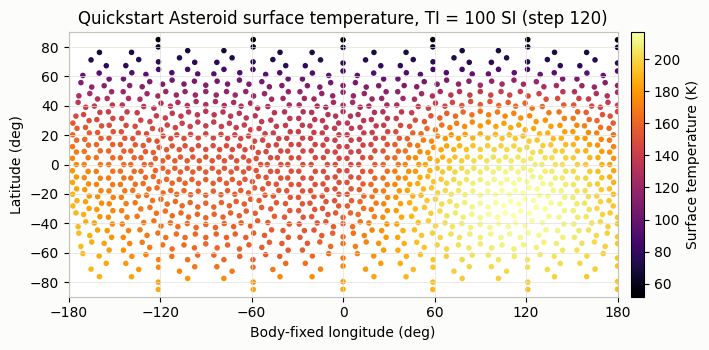

Step 120: T range 51.9-216.7 K (713 distinct values of 1280 faces)


In [15]:
EPOCH_STEP = 120  # second rotation (steps 96-191), roughly mid-afternoon local time
T_epoch = load_bin(BASE_OUT / "temperature" / f"temperature_{EPOCH_STEP:04d}.bin")

fig, ax = plt.subplots(figsize=(7.5, 3.6), facecolor="#fcfcfb")
sc = ax.scatter(lon, lat, c=T_epoch, cmap="inferno", s=16, edgecolors="none")
cbar = fig.colorbar(sc, ax=ax, pad=0.02)
cbar.set_label("Surface temperature (K)")
ax.set_xlabel("Body-fixed longitude (deg)")
ax.set_ylabel("Latitude (deg)")
ax.set_title(f"Quickstart Asteroid surface temperature, TI = 100 SI (step {EPOCH_STEP})")
ax.set_xlim(-180, 180)  # mesh.ply longitude convention is [-180, 180], not [0, 360] --
                        # confirmed from lon.min()/lon.max() below; an earlier [0, 360]
                        # xlim silently clipped the western hemisphere out of the plot
ax.set_ylim(-90, 90)
ax.set_xticks(range(-180, 181, 60))
ax.grid(color="#e1e0d9", linewidth=0.5)
for spine in ax.spines.values():
    spine.set_color("#c3c2b7")
plt.tight_layout()
plt.show()

print(f"Step {EPOCH_STEP}: T range {T_epoch.min():.1f}-{T_epoch.max():.1f} K "
      f"({np.unique(np.round(T_epoch, 1)).size} distinct values of {T_epoch.size} faces)")

A warm afternoon lobe, a cold night hemisphere, and — because
`pole_dec_deg = 90` pins the sub-solar latitude at the equator for the whole
run — the poles sit at an intermediate, roughly constant temperature (near-
permanent grazing sunlight, the same edge case flagged in the QA section
above; not a bug, just a consequence of this config's deliberately simplified
zero-obliquity spin).

### 5.2 Equatorial diurnal curve

We want temperature vs. **local solar time (LST)**, the standard planetary-
science convention: LST is an angle (the Sun's hour angle) always expressed
on a 24-hour clock with local noon = 12h, *regardless* of the body's actual
rotation period. For every equatorial-band face we find its own local noon
(the timestep where its `direct_solar` flux peaks — flux has no thermal
inertia, so this is exact by construction) and bin every equatorial face's
temperature by LST relative to that face's own noon. This is deliberately an
**ensemble average over all 220 equatorial faces**, not one cherry-picked
face, so any single face's mesh-triangulation idiosyncrasies wash out.

In [16]:
def local_solar_time_curve(out_dir, lat_max=10.0, n_bins=48):
    lat_i, lon_i = read_ply_face_latlon(out_dir / "mesh.ply")
    eq_idx = np.where(np.abs(lat_i) < lat_max)[0]

    tfiles = sorted(glob.glob(str(out_dir / "temperature" / "temperature_*.bin")))
    ffiles = sorted(glob.glob(str(out_dir / "direct_solar" / "direct_solar_*.bin")))
    n_steps = len(tfiles)
    n_per_rot = n_steps // 2  # this tutorial's configs always output 2 rotations
    # Use the SECOND rotation only -- periodicity between rotation 1 and 2 was
    # confirmed during development (max|delta T| = 0.25 K at 50-rotation
    # equilibration), so the second rotation is the settled, periodic one.
    T2 = np.stack([load_bin(f) for f in tfiles[n_per_rot:]])   # (n_per_rot, n_faces)
    F2 = np.stack([load_bin(f) for f in ffiles[n_per_rot:]])   # (n_per_rot, n_faces)

    noon_step = np.argmax(F2[:, eq_idx], axis=0)               # per-face local-noon step
    steps = np.arange(n_per_rot)[:, None]
    lst = ((steps - noon_step[None, :]) * (24.0 / n_per_rot) + 12.0) % 24.0
    T_eq = T2[:, eq_idx]

    lst_flat, T_flat = lst.ravel(), T_eq.ravel()
    edges = np.linspace(0, 24, n_bins + 1)
    idx = np.clip(np.digitize(lst_flat, edges) - 1, 0, n_bins - 1)
    centers = 0.5 * (edges[:-1] + edges[1:])
    mean_T = np.array([T_flat[idx == b].mean() for b in range(n_bins)])
    lo_T = np.array([np.percentile(T_flat[idx == b], 25) for b in range(n_bins)])
    hi_T = np.array([np.percentile(T_flat[idx == b], 75) for b in range(n_bins)])
    return centers, mean_T, lo_T, hi_T, eq_idx.size


lst100, T100, lo100, hi100, n_eq100 = local_solar_time_curve(BASE_OUT)
print(f"{n_eq100} equatorial faces binned into {len(lst100)} local-solar-time bins")

220 equatorial faces binned into 48 local-solar-time bins


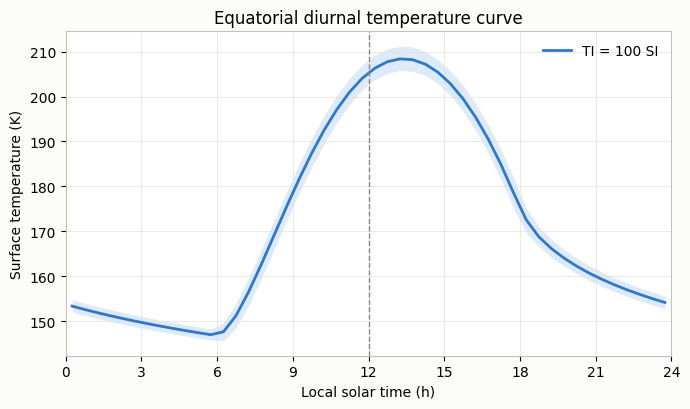

Peak temperature at LST = 13.25 h (75 min after local noon)
Diurnal amplitude (band mean Tmax - Tmin): 61.4 K


In [17]:
fig, ax = plt.subplots(figsize=(7, 4.2), facecolor="#fcfcfb")
ax.plot(lst100, T100, color="#2a78d6", lw=2, label="TI = 100 SI")
ax.fill_between(lst100, lo100, hi100, color="#2a78d6", alpha=0.15, linewidth=0)
ax.axvline(12, color="#898781", lw=1, linestyle="--")
ax.set_xlabel("Local solar time (h)")
ax.set_ylabel("Surface temperature (K)")
ax.set_title("Equatorial diurnal temperature curve")
ax.set_xlim(0, 24)
ax.set_xticks(range(0, 25, 3))
ax.legend(frameon=False)
ax.grid(color="#e1e0d9", linewidth=0.5)
for spine in ax.spines.values():
    spine.set_color("#c3c2b7")
plt.tight_layout()
plt.show()

peak_lst_100 = lst100[np.argmax(T100)]
print(f"Peak temperature at LST = {peak_lst_100:.2f} h "
      f"({(peak_lst_100 - 12) * 60:.0f} min after local noon)")
print(f"Diurnal amplitude (band mean Tmax - Tmin): {T100.max() - T100.min():.1f} K")

The band shading is the inter-face (25th–75th percentile) spread at fixed
LST — small, confirming the ensemble-average curve is representative rather
than hiding face-to-face scatter.

### 5.3 The signature plot: thermal-inertia amplitude damping and phase lag

Same construction, now overlaying the TI = 200 SI run.

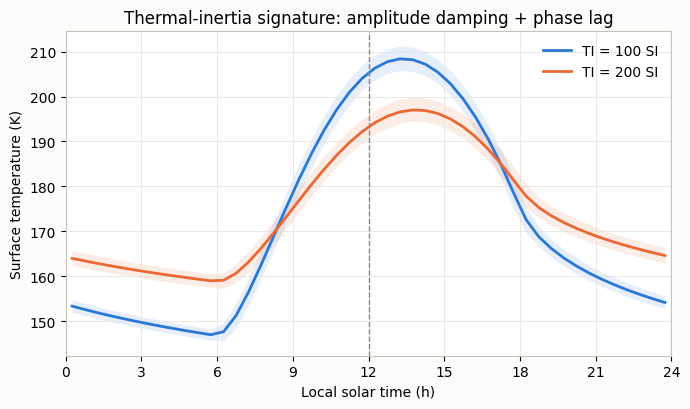

TI=100: peak LST = 13.25 h   amplitude = 61.4 K
TI=200: peak LST = 13.75 h   amplitude = 38.0 K
Peak shifted 30 minutes later; amplitude fell 23.4 K (38% reduction) at 2x the thermal inertia.


In [18]:
lst200, T200, lo200, hi200, n_eq200 = local_solar_time_curve(TI200_OUT)

fig, ax = plt.subplots(figsize=(7, 4.2), facecolor="#fcfcfb")
ax.plot(lst100, T100, color="#2a78d6", lw=2, label="TI = 100 SI")
ax.fill_between(lst100, lo100, hi100, color="#2a78d6", alpha=0.12, linewidth=0)
ax.plot(lst200, T200, color="#eb6834", lw=2, label="TI = 200 SI")
ax.fill_between(lst200, lo200, hi200, color="#eb6834", alpha=0.12, linewidth=0)
ax.axvline(12, color="#898781", lw=1, linestyle="--")
ax.set_xlabel("Local solar time (h)")
ax.set_ylabel("Surface temperature (K)")
ax.set_title("Thermal-inertia signature: amplitude damping + phase lag")
ax.set_xlim(0, 24)
ax.set_xticks(range(0, 25, 3))
ax.legend(frameon=False)
ax.grid(color="#e1e0d9", linewidth=0.5)
for spine in ax.spines.values():
    spine.set_color("#c3c2b7")
plt.tight_layout()
plt.show()

peak_lst_200 = lst200[np.argmax(T200)]
amp100 = T100.max() - T100.min()
amp200 = T200.max() - T200.min()
print(f"TI=100: peak LST = {peak_lst_100:.2f} h   amplitude = {amp100:.1f} K")
print(f"TI=200: peak LST = {peak_lst_200:.2f} h   amplitude = {amp200:.1f} K")
print(f"Peak shifted {(peak_lst_200 - peak_lst_100) * 60:.0f} minutes later; "
      f"amplitude fell {amp100 - amp200:.1f} K "
      f"({100 * (amp100 - amp200) / amp100:.0f}% reduction) at 2x the thermal inertia.")

**The lag shows clearly at this TI**: the peak moves from LST ≈ 13.25 h
to LST ≈ 13.75 h (about half an hour later, on this notebook's measured run)
as TI doubles, and the whole curve visibly flattens toward the mean. Both are
the textbook thermal-inertia signature (Spencer et al. 1989).

### 5.4 Quantifying the asymmetry directly — and an honest surprise

A second way to look at the same effect: for a range of offsets $x$ hours
from local noon, plot $T(\text{noon}+x) - T(\text{noon}-x)$. A perfectly
symmetric (zero-thermal-inertia) surface would give exactly zero everywhere;
any positive value is the thermal lag.

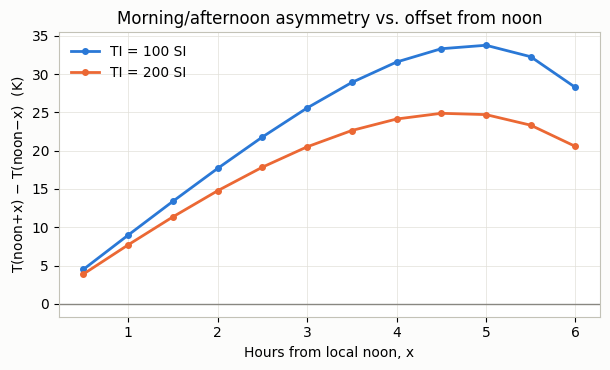

Asymmetry (K) at x = [0.5, 1.0, 1.5, 2.0, 2.5, 3.0, 3.5, 4.0, 4.5, 5.0, 5.5, 6.0]
  TI=100: [4.5, 9.0, 13.4, 17.7, 21.8, 25.6, 28.9, 31.6, 33.3, 33.8, 32.3, 28.2]
  TI=200: [3.9, 7.7, 11.4, 14.8, 17.8, 20.5, 22.6, 24.1, 24.9, 24.7, 23.3, 20.5]


In [19]:
def asymmetry(lst, T):
    x = np.linspace(0.5, 6.0, 12)
    T_after = np.interp(12 + x, lst, T, period=24)
    T_before = np.interp(12 - x, lst, T, period=24)
    return x, T_after - T_before


x100, d100 = asymmetry(lst100, T100)
x200, d200 = asymmetry(lst200, T200)

fig, ax = plt.subplots(figsize=(6.2, 3.8), facecolor="#fcfcfb")
ax.plot(x100, d100, color="#2a78d6", lw=2, marker="o", ms=4, label="TI = 100 SI")
ax.plot(x200, d200, color="#eb6834", lw=2, marker="o", ms=4, label="TI = 200 SI")
ax.axhline(0, color="#898781", lw=1)
ax.set_xlabel("Hours from local noon, x")
ax.set_ylabel(r"T(noon+x) $-$ T(noon$-$x)  (K)")
ax.set_title("Morning/afternoon asymmetry vs. offset from noon")
ax.legend(frameon=False)
ax.grid(color="#e1e0d9", linewidth=0.5)
for spine in ax.spines.values():
    spine.set_color("#c3c2b7")
plt.tight_layout()
plt.show()

print("Asymmetry (K) at x =", np.round(x100, 1).tolist())
print("  TI=100:", np.round(d100, 1).tolist())
print("  TI=200:", np.round(d200, 1).tolist())

Both curves are positive everywhere (afternoon is always warmer than the
time-mirrored morning — the correct sign), **but the TI = 200 curve sits
*below* the TI = 100 curve at every offset**, not above it. That is not a
mistake in the plot; it is a real, measured result: the peak occurs later in
absolute LST at higher TI (Section 5.3), but the *absolute* K-scale asymmetry
also depends on the overall diurnal amplitude, which collapses faster (61 K →
38 K) than the phase lag grows over this particular TI range. **A larger
phase lag does not automatically mean a larger absolute morning/afternoon
temperature difference** — the two effects can partially offset, which is
exactly why real thermophysical model fits use the *whole* diurnal curve
shape (amplitude and phase together via a dimensionless thermal parameter,
Section 6), not a single asymmetry number, to solve for TI.

### 5.5 Optional: a thermal-lightcurve seed

Real asteroid thermal *lightcurves* — disk-integrated flux modulating as a
non-spherical, rotating body turns a changing silhouette and thermal state
toward the observer — are a shape effect as much as a thermophysical one.
This tutorial's body is a perfect sphere with spatially uniform properties,
so there is, correctly, **no lightcurve signal to show here**: any
"sub-observer temperature vs. rotation phase" plot on this body is just the
single-face diurnal curve from Section 5.2 relabeled, which would be a
misleading way to introduce the idea. The honest statement is the setup for
Exercise 4: load a non-spherical DAMIT shape (`generic_body.shape.type:
custom_mesh`) and repeat this notebook's Section 5.2 construction using each
face's *distance-corrected, viewing-geometry-weighted* emission instead of a
single face's temperature — that is where a real thermal lightcurve comes
from, and it needs shape, not just thermal inertia.

## 6. Interpretation

**Thermal inertia, physically.** $TI = \sqrt{k\rho c_p}$ sets how far a
diurnal thermal wave penetrates before the next day/night flip reverses it
(the diurnal skin depth $\ell_s = \sqrt{\kappa P/\pi}$, with $\kappa = k/(\rho
c_p)$ and $P$ the rotation period — about 6.3 mm for this tutorial's TI = 100
config at its 5 h spin period). A dimensionless combination, the **thermal
parameter**

$$\Theta = \frac{TI\sqrt{\omega}}{\varepsilon\sigma T_{eq}^3}$$

(Spencer, Lebofsky & Sykes 1989; $\omega$ = rotation rate, $T_{eq}$ = the
zero-inertia subsolar equilibrium temperature), governs the whole diurnal
curve shape: $\Theta \to 0$ is an instantaneous-equilibrium ("fluffy dust")
surface with a huge day/night swing and zero lag; $\Theta \to \infty$ is
perfectly conductive with **no** diurnal variation at all and (in the limit)
the peak lags all the way to a quarter-rotation. Our TI = 100 → 200 pair is a
finite step along that curve — exactly what Section 5 measured.

**The Yarkovsky connection.** Because the temperature peak lags local noon,
the asteroid re-radiates more thermal photons from its *afternoon* hemisphere
than a naive instantaneous-equilibrium body would — and photon emission
carries momentum. For a body spinning the way this tutorial's config does
(spin pole roughly normal to the orbit, i.e. an ordinary prograde equatorial
rotator), that recoil has a small component *along* the orbital velocity,
which over millions of years measurably drifts the semi-major axis outward
(inward for a retrograde rotator) — the Yarkovsky effect (Bottke et al. 2006).
Thermal inertia is the parameter that sets how large this effect is: TI → 0
or TI → ∞ both suppress it (no lag, or no asymmetry left to lag), and it
peaks at intermediate TI — the same $\Theta \sim 1$ regime real small NEAs
often sit in, which is exactly why Yarkovsky-drift modeling and thermal-
inertia measurement are the same scientific problem in practice.

**Connection to real observations.** Nothing in this notebook is
observational, but the pipeline it demonstrates is the actual one: ground-
and space-based thermal-infrared photometry (radiometry) measures a disk-
integrated flux at one or more wavelengths and rotational phases; a
thermophysical model — structurally the same conduction solve as this
tutorial's config, just fit to real shape/spin/albedo — is run over a grid of
candidate thermal inertias, and the TI that reproduces the observed flux
(amplitude *and* phase, per Section 5.4's lesson) is reported. The same
physics underlies flyby/rendezvous thermal-IR imaging, which measures
`T(local time)` directly, the way Section 5.2's plot does, rather than only a
disk-integrated number.

## 7. Exercises

Set `RUN_EXERCISES = True` in the cell below to execute these (each launches
1–4 more ~25–35 s CPU runs; left off by default so re-running this notebook
top-to-bottom stays fast). All three reuse `run_ptm()`,
`local_solar_time_curve()`, `load_bin()`, and `read_ply_face_latlon()` from
above.

In [20]:
RUN_EXERCISES = False  # flip to True to actually launch the runs below

try:
    import yaml  # PyYAML -- only needed if you flip RUN_EXERCISES on
except ImportError:
    yaml = None
    if RUN_EXERCISES:
        raise SystemExit("RUN_EXERCISES=True needs PyYAML: pip install pyyaml")


def write_variant(overrides, out_name):
    # Load the base config, apply a dict of {dotted.path: value} overrides,
    # write it to examples/<out_name>.yaml, return the relative path.
    with open(REPO_ROOT / "examples" / "quickstart_asteroid_diurnal.yaml") as f:
        cfg = yaml.safe_load(f)
    for dotted, value in overrides.items():
        node = cfg
        keys = dotted.split(".")
        for k in keys[:-1]:
            node = node[k]
        node[keys[-1]] = value
    cfg["output"]["directory"] = f"output/{out_name}"
    out_path = REPO_ROOT / "examples" / f"{out_name}.yaml"
    with open(out_path, "w") as f:
        yaml.safe_dump(cfg, f, sort_keys=False)
    return f"examples/{out_name}.yaml", REPO_ROOT / "output" / out_name


print("RUN_EXERCISES =", RUN_EXERCISES)

RUN_EXERCISES = False


### Exercise 1 — Vary thermal inertia

Sweep `ks`/`kd` (hence TI) over the solver's validated working range and plot
amplitude and peak-LST vs. TI. Recall $TI \propto \sqrt{ks}$ at fixed
`rhos`/`cp0`, so hitting TI = {32, 100, 316} needs `ks` = TI²/(1500·800) =
{0.000853, 0.008333, 0.0833} W/m/K.

In [21]:
if RUN_EXERCISES:
    TI_targets = [32.0, 100.0, 200.0, 316.0]
    rhos, cp0 = 1500.0, 800.0
    results = []
    for TI in TI_targets:
        ks = TI ** 2 / (rhos * cp0)
        cfg_rel, out_dir = write_variant(
            {"generic_body.surface.ks": ks, "generic_body.surface.kd": ks},
            f"_ex1_ti{int(TI)}")
        run_ptm(cfg_rel, f"TI={TI:.0f}")
        lst, T, lo, hi, n = local_solar_time_curve(out_dir)
        results.append((TI, T.max() - T.min(), lst[np.argmax(T)]))

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.6), facecolor="#fcfcfb")
    TIs, amps, peaks = zip(*results)
    ax1.plot(TIs, amps, "o-", color="#2a78d6")
    ax1.set_xlabel("Thermal inertia (SI)"); ax1.set_ylabel("Diurnal amplitude (K)")
    ax2.plot(TIs, peaks, "o-", color="#eb6834")
    ax2.set_xlabel("Thermal inertia (SI)"); ax2.set_ylabel("Peak local solar time (h)")
    for ax in (ax1, ax2):
        ax.grid(color="#e1e0d9", linewidth=0.5)
    plt.tight_layout(); plt.show()
else:
    print("Skipped (RUN_EXERCISES = False).")

Skipped (RUN_EXERCISES = False).


### Exercise 2 — Vary spin rate

Change `generic_body.spin.period_hours` (try 2 h and 10 h) at fixed TI = 100.
What matters for the diurnal curve is not TI alone but the thermal parameter
$\Theta \propto TI\sqrt{\omega}$ (Section 6) — a faster spin raises $\omega$
and therefore $\Theta$ *even at the same TI*, so a 2 h rotator should show
**more** damping than the 5 h baseline, and a 10 h rotator **less**. Remember
to also lower `equilibration_steps_per_day` proportionally if you shorten the
period drastically, so the pinned per-rotation sample count doesn't
implicitly change.

In [22]:
if RUN_EXERCISES:
    for period_h in (2.0, 10.0):
        n_rot_steps = 48  # keep the same steps/rotation as the baseline
        steps_per_day = n_rot_steps * 24.0 / period_h
        cfg_rel, out_dir = write_variant(
            {"generic_body.spin.period_hours": period_h,
             "simulation.duration_days": 2 * period_h / 24.0,
             "simulation.timesteps": 2 * n_rot_steps,
             "thermal.equilibration_steps_per_day": steps_per_day},
            f"_ex2_period{int(period_h)}h")
        run_ptm(cfg_rel, f"period={period_h:.0f}h")
        lst, T, lo, hi, n = local_solar_time_curve(out_dir)
        print(f"  period={period_h:.0f} h: amplitude={T.max()-T.min():.1f} K, "
              f"peak LST={lst[np.argmax(T)]:.2f} h")
else:
    print("Skipped (RUN_EXERCISES = False).")

Skipped (RUN_EXERCISES = False).


### Exercise 3 — Add eccentricity

Set `generic_body.orbit.eccentricity` to, say, 0.2. **Caveat worth stating
up front**: this tutorial's 2-rotation (~10-hour) output window is far too
short to see any effect of orbital eccentricity — the heliocentric distance
barely changes over a few hours on a multi-year orbit. An eccentricity edit
only becomes visible if you also extend `simulation.duration_days` to a
sizeable fraction of the orbital period (`generic_body.orbit.semi_major_axis_au
= 2.7` → an ~4.4-year orbit) — which moves this well outside "laptop-tutorial"
territory (see [Tutorial 02](../02_lunar_diurnal_icosphere.md)'s equivalent
month-scale lunar run for a sense of the cost curve). This exercise is a
pointer, not a to-run-here cell: try a duration of a few percent of the orbital
period and look for a slowly-drifting mean temperature riding on top of the
same diurnal cycle.

## Provenance

This notebook was executed end to end (`jupyter nbconvert --execute`) against
the binary and commit printed in Section 1, in the `europa_viz` conda
environment. Re-running it from a clean clone reproduces the same runs
(same seeds are not needed — the model is deterministic given the config) and
the same qualitative plots; exact K values may drift by build-to-build engine
changes (see [Tutorial 02](../02_lunar_diurnal_icosphere.md)'s own note about
this) — that is expected, not a bug, and is exactly why Section 3's QA cells
check *signal* and *sign*, not hard-coded numbers.